# Image Processing Practical File 1 — 10 Programs

**Purpose:** Solutions covering basic image reading, format conversion, transformations, color spaces, and MSE evaluation.

## Program 1 — Read and display `flower.jpg` using OpenCV

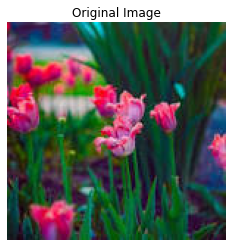

In [1]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread("flower.jpg")
if image is None:
    raise FileNotFoundError("Could not find flower.jpg. Place it beside this notebook or update the path.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

**Explanation:** `cv2.imread()` loads the image. OpenCV reads colour channels as BGR, so `cvtColor()` converts it to RGB for correct Matplotlib colours.

## Program 2 — Print dimensions and data type of `scene.jpg`

In [2]:
import cv2

image = cv2.imread("scene.jpg")
if image is None:
    raise FileNotFoundError("Could not find scene.jpg. Check its path.")

height, width = image.shape[:2]
channels = 1 if image.ndim == 2 else image.shape[2]

print("Height:", height, "pixels")
print("Width:", width, "pixels")
print("Channels:", channels)
print("Data type:", image.dtype)

Height: 452 pixels
Width: 678 pixels
Channels: 3
Data type: uint8


**Explanation:** `shape` provides height, width, and (for a colour image) channel count. `dtype` reports the pixel data type, commonly `uint8`.

## Program 3 — Convert a colour image to grayscale and save `output_gray.jpg`

Saved successfully: True


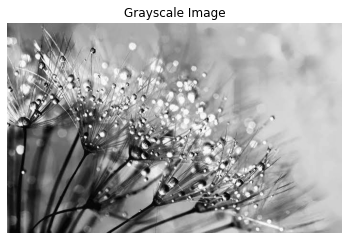

In [3]:
import cv2

image = cv2.imread("colour.jpg")
if image is None:
    raise FileNotFoundError("Could not find colour.jpg. Change this filename if your image has another name.")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
saved = cv2.imwrite("output_gray.jpg", gray)
print("Saved successfully:", saved)

import matplotlib.pyplot as plt
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

**Explanation:** Grayscale represents each pixel with one intensity value instead of three colour channels. `imwrite()` saves the result.

## Program 4 — Open and display `sunset.png` using Pillow

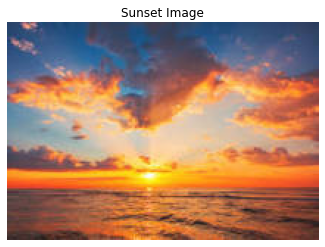

In [4]:
from PIL import Image
import matplotlib.pyplot as plt

with Image.open("sunset.png") as image:
    image.load()
    plt.imshow(image)
    plt.title("Sunset Image")
    plt.axis("off")
    plt.show()

**Explanation:** Pillow's `Image.open()` opens common image formats. The `with` statement safely closes the file after use.

## Program 5 — Resize an image to 50% of its original size

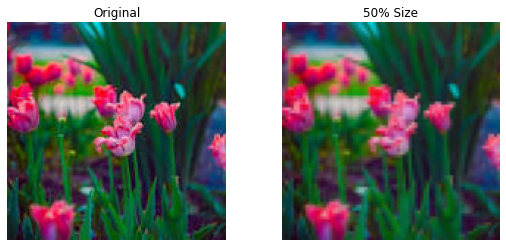

Original (width, height): (149, 148)
Resized (width, height): (74, 74)


In [5]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread("flower.jpg")
if image is None:
    raise FileNotFoundError("Could not find flower.jpg.")

height, width = image.shape[:2]
new_size = (max(1, width // 2), max(1, height // 2))
resized = cv2.resize(image, new_size, interpolation=cv2.INTER_AREA)

plt.figure(figsize=(9, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
plt.title("50% Size")
plt.axis("off")
plt.show()
print("Original (width, height):", (width, height))
print("Resized (width, height):", new_size)

**Explanation:** The new width and height are each half of the original. `INTER_AREA` is a good default for shrinking images.

## Program 6 — Crop the central 200 × 200 pixel region and display it

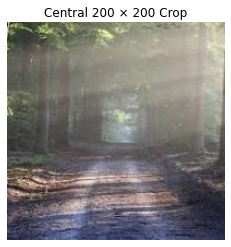

In [1]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread("scene.jpg")
if image is None:
    raise FileNotFoundError("Could not find scene.jpg.")

height, width = image.shape[:2]
if height < 200 or width < 200:
    raise ValueError("The image must be at least 200 x 200 pixels.")

x_start = (width - 200) // 2
y_start = (height - 200) // 2
crop = image[y_start:y_start + 200, x_start:x_start + 200]

plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
plt.title("Central 200 × 200 Crop")
plt.axis("off")
plt.show()

**Explanation:** Images are indexed as `[y, x]`, or `[row, column]`. The starting coordinates are calculated so the crop is centred.

## Program 7 — Rotate an image 90° clockwise

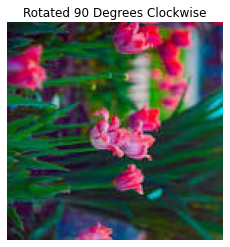

In [9]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread("flower.jpg")
if image is None:
    raise FileNotFoundError("Could not find flower.jpg.")

rotated = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
plt.imshow(cv2.cvtColor(rotated, cv2.COLOR_BGR2RGB))
plt.title("Rotated 90 Degrees Clockwise")
plt.axis("off")
plt.show()

**Explanation:** `cv2.rotate()` applies a right-angle rotation without needing a manually calculated rotation matrix.

## Program 8 — Flip `car.jpg` left-to-right

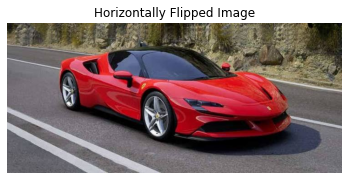

In [10]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread("car.jpg")
if image is None:
    raise FileNotFoundError("Could not find car.jpg.")

flipped = cv2.flip(image, 1)  # 1 means horizontal flip
plt.imshow(cv2.cvtColor(flipped, cv2.COLOR_BGR2RGB))
plt.title("Horizontally Flipped Image")
plt.axis("off")
plt.show()

**Explanation:** In OpenCV, flip code `1` mirrors the image horizontally; `0` flips vertically, and `-1` flips both directions.

## Program 9 — Convert RGB to HSV and display H, S, and V channels

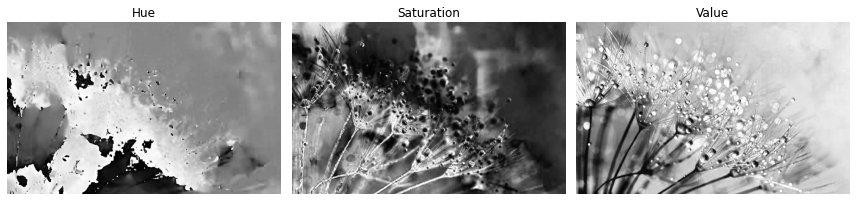

In [11]:
import cv2
import matplotlib.pyplot as plt

image_bgr = cv2.imread("colour.jpg")
if image_bgr is None:
    raise FileNotFoundError("Could not find colour.jpg.")

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
hue, saturation, value = cv2.split(hsv)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(hue, cmap="gray")
plt.title("Hue")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(saturation, cmap="gray")
plt.title("Saturation")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(value, cmap="gray")
plt.title("Value")
plt.axis("off")
plt.tight_layout()
plt.show()

**Explanation:** HSV separates colour type (Hue), colour strength (Saturation), and brightness (Value). OpenCV's HSV hue range is typically 0–179 for 8-bit images.

## Program 10 — Calculate MSE between `img1.jpg` and `img2.jpg`

In [14]:
import cv2
import numpy as np

img1 = cv2.imread("img1.jpg", cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread("img2.jpg", cv2.IMREAD_GRAYSCALE)

if img1 is None or img2 is None:
    raise FileNotFoundError("Ensure both img1.jpg and img2.jpg are in the notebook folder.")
if img1.shape != img2.shape:
    raise ValueError(f"Images must have the same dimensions. Got {img1.shape} and {img2.shape}.")

mse = np.mean((img1.astype(np.float64) - img2.astype(np.float64)) ** 2)
print("Mean Squared Error (MSE):", mse)

Mean Squared Error (MSE): 224.1312713623047


**Explanation:** MSE is the average squared pixel difference between two images. An MSE of `0` means the grayscale images are identical. A larger MSE indicates a larger pixel-wise difference.